In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the supplied dataset
df = pd.read_csv("iris.csv")
df.head()

,Sepal_length,Sepal_width,Petal_length,Petal_width,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [3]:
# First five records
display(df.head())

# Dataset dimensions and column names
print("Dataset dimensions (rows, columns):", df.shape)
print("\\nColumn names:", df.columns.tolist())

# Data types and non-null counts
print("\\nData types:")
print(df.dtypes)
print("\\nSummary information:")
df.info()

# Missing values in each column
print("\\nMissing values:")
print(df.isnull().sum())

,Sepal_length,Sepal_width,Petal_length,Petal_width,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


Dataset dimensions (rows, columns): (150, 5)
\nColumn names: ['Sepal_length', 'Sepal_width', 'Petal_length', 'Petal_width', 'Species']
\nData types:
Sepal_length    float64
Sepal_width     float64
Petal_length    float64
Petal_width     float64
Species             str
dtype: object
\nSummary information:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Sepal_length  150 non-null    float64
 1   Sepal_width   150 non-null    float64
 2   Petal_length  150 non-null    float64
 3   Petal_width   150 non-null    float64
 4   Species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB
\nMissing values:
Sepal_length    0
Sepal_width     0
Petal_length    0
Petal_width     0
Species         0
dtype: int64


In [4]:
numeric_cols = df.select_dtypes(include=np.number).columns

results = []
for col in numeric_cols:
    values = df[col].to_numpy()
    results.append({
        "Attribute": col,
        "Mean": np.mean(values),
        "Median": np.median(values),
        "Standard deviation (population)": np.std(values, ddof=0),
        "Minimum": np.min(values),
        "Maximum": np.max(values)
    })

numpy_summary = pd.DataFrame(results).set_index("Attribute")
display(numpy_summary)

correlation = np.corrcoef(df["Sepal_length"], df["Petal_length"])[0, 1]
print("Correlation between sepal length and petal length:", round(correlation, 4))

,Mean,Median,Standard deviation (population),Minimum,Maximum
Attribute,,,,,
Sepal_length,5.843333,5.80,0.825301,4.3,7.9
Sepal_width,3.054000,3.00,0.432147,2.0,4.4
Petal_length,3.758667,4.35,1.758529,1.0,6.9
Petal_width,1.198667,1.30,0.760613,0.1,2.5


Correlation between sepal length and petal length: 0.8718


In [5]:
# Mean of each numerical attribute for each species
species_means = df.groupby("Species")[numeric_cols].mean()
display(species_means)

# Species with the highest average petal length
highest_species = species_means["Petal_length"].idxmax()
highest_mean = species_means["Petal_length"].max()
print(f"Highest average petal length: {highest_species} ({highest_mean:.2f} cm)")

# Descriptive statistics for each species
display(df.groupby("Species")[numeric_cols].describe())

# Number of samples per species
display(df["Species"].value_counts().rename("Sample count").to_frame())

,Sepal_length,Sepal_width,Petal_length,Petal_width
Species,,,,
Iris-setosa,5.006,3.418,1.464,0.244
Iris-versicolor,5.936,2.770,4.260,1.326
Iris-virginica,6.588,2.974,5.552,2.026


Highest average petal length: Iris-virginica (5.55 cm)


Sepal_length                                              \
                       count   mean       std  min    25%  50%  75%  max   
Species                                                                    
Iris-setosa             50.0  5.006  0.352490  4.3  4.800  5.0  5.2  5.8   
Iris-versicolor         50.0  5.936  0.516171  4.9  5.600  5.9  6.3  7.0   
Iris-virginica          50.0  6.588  0.635880  4.9  6.225  6.5  6.9  7.9   

                Sepal_width         ... Petal_length      Petal_width         \
                      count   mean  ...          75%  max       count   mean   
Species                             ...                                        
Iris-setosa            50.0  3.418  ...        1.575  1.9        50.0  0.244   
Iris-versicolor        50.0  2.770  ...        4.600  5.1        50.0  1.326   
Iris-virginica         50.0  2.974  ...        5.875  6.9        50.0  2.026   

                                                    
                      std  min  25%  50%  75%  max  
Species                                             
Iris-setosa      0.107210  0.1  0.2  0.2  0.3  0.6  
Iris-versicolor  0.197753  1.0  1.2  1.3  1.5  1.8  
Iris-virginica   0.274650  1.4  1.8  2.0  2.3  2.5  

[3 rows x 32 columns]

,Sample count
Species,
Iris-setosa,50
Iris-versicolor,50
Iris-virginica,50


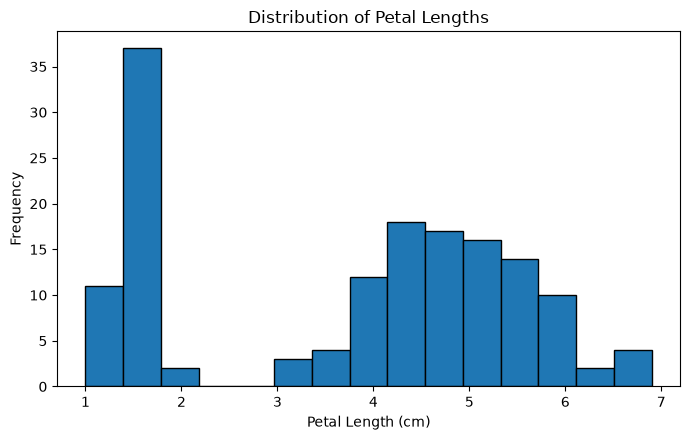

In [6]:
# Histogram of petal lengths
plt.figure(figsize=(7, 4.5))
plt.hist(df["Petal_length"], bins=15, edgecolor="black")
plt.title("Distribution of Petal Lengths")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

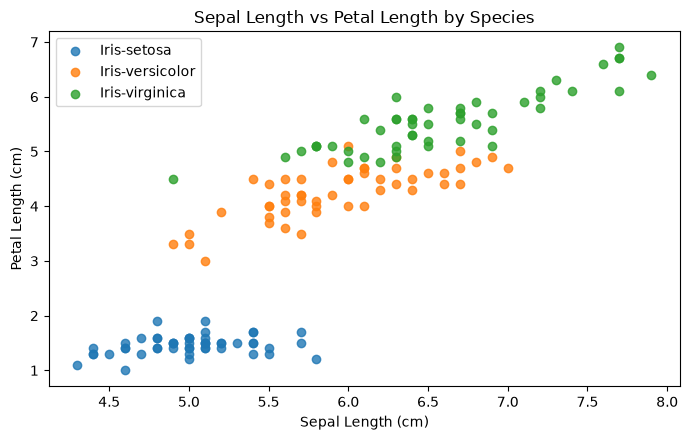

In [7]:
# Scatter plot, with a separate colour for each species
plt.figure(figsize=(7, 4.5))
for species, group in df.groupby("Species"):
    plt.scatter(group["Sepal_length"], group["Petal_length"], label=species, alpha=0.8)
plt.title("Sepal Length vs Petal Length by Species")
plt.xlabel("Sepal Length (cm)")
plt.ylabel("Petal Length (cm)")
plt.legend()
plt.tight_layout()
plt.show()

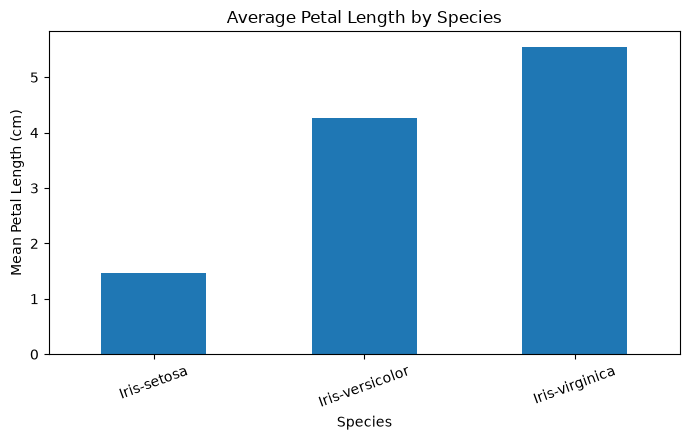

In [8]:
# Bar chart of average petal length
species_means["Petal_length"].plot(kind="bar", figsize=(7, 4.5))
plt.title("Average Petal Length by Species")
plt.xlabel("Species")
plt.ylabel("Mean Petal Length (cm)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()